<center> <h1> <span style="color:red"><u>PROJET : Analyse de Survie "Titanic" <u></span></h1> </center>

<span style="color:red"><u>**SOMMAIRE**<u></span> :    
**1-Introduction generale**  
**2-Section Pédagogique "Concepts Nouveaux"**  
**3-Développement Technique :**  
    **3.1- Acquisition et Nettoyage**  
    **3.2- Analyse Sociologique**  
    **3.3- Modélisation (Random Forest)**  
    **3.4- Visualisations Avancées**  
**4-Conclusion Générale**  
**5-Bilan Personnel**

<span style="color:blue"><u>**1-Introduction Generale**<u></span>

Le naufrage du RMS Titanic est l'une des catastrophes maritimes les plus célèbres de l'histoire. Le 15 avril 1912, lors de son voyage inaugural, le Titanic a sombré après avoir heurté un iceberg, causant la mort de 1 502 passagers et membres d'équipage sur les 2 224 présents à bord. Cette tragédie retentissante a choqué la communauté internationale et a conduit à une amélioration spectaculaire des réglementations de sécurité sur les navires.

L'une des raisons pour lesquelles ce naufrage a entraîné une telle perte de vies humaines était le manque de canots de sauvetage pour l'ensemble des passagers et de l'équipage. Bien que la survie ait comporté une part de chance, certains groupes de personnes étaient statistiquement plus susceptibles de survivre que d'autres, notamment les femmes, les enfants et les passagers de la classe supérieure

L’objectif de ce projet est d’analyser les facteurs ayant influencé la survie des passagers à travers une approche en plusieurs étapes : nettoyage des données, analyse sociologique, visualisation statistique et modélisation par classification.

<span style="color:blue"><u>**2-Section Pédagogique "Concepts Nouveaux"**<u></span>

Durant ce projet et surtout dans les deux dérnières parties, j'ai utilisée une librairie et un modele de classification sont comme suit :  
**1- La bibliotheque Scikit-learn :**
    C'est une bibliothèque open-source en Python qui fournit des outils simples et efficaces pour l’apprentissage automatique (classification, régression, clustering, évaluation de modèles, etc.). 
    Elle permet de Construire des modèles de classification (ex : Random Forest, KNN, SVM), Faire de la régression, Évaluer les modèles (accuracy, matrice de confusion), Séparer train/test et Prétraiter les données.

**2-le modele RandomForest :**
    c'est un algorithme de machine learning conçu pour obtenir une prédiction fiable grâce à un système de sous-espaces aléatoires.
    le random forest est composé de plusieurs arbres de décision, entrainés de manière indépendante sur des sous-ensembles du dataset d'apprentissage.
    Chacun produit une estimation, et c'est la combinaison des résultats qui va donner la prédiction finale qui se traduit par une variance réduite. En somme, il s'agit de s'inspirer de différents avis, traitant un même problème, pour mieux l'appréhender, Chaque modèle est distribué de façon aléatoire en sous-ensembles d'arbres décisionnels.
    Dans un random forest de classification, l'estimation finale consiste à choisir la catégorie de réponse la plus fréquente. Plutôt qu'utiliser tous les résultats obtenus, on procède à une sélection en recherchant la prévision qui revient le plus souvent.
    Dans ce projet, Random Forest a été utilisé afin de prédire la survie des passagers en fonction de leurs caractéristiques (âge, sexe, classe sociale), car il offre de bonnes performances en classification et gère efficacement les relations non linéaires entre variables.

**3-Train-Test Split** : C'est le concept 80% 20%, l'idee est de divisee la dataset en deux groupes :  
**-Train**: le moele utilise 80% des donnees pour apprendre les relations  
         **-Test** : c'est le 20% restants. Ces données sont cachées au modèle pendant "Train". Elles servent d'examen final pour vérifier si le modèle est capable de prédire correctement sur des passagers qu'il n'a jamais vus.

**4-heatmap**: c'est une représentation graphique d’une matrice numérique où les valeurs sont représentées par des couleurs.
Dans ce projet, elle est utilisée pour visualiser la matrice de corrélation entre les variables.
La corrélation de Pearson mesure la relation linéaire entre deux variables quantitatives :
r = Cov(X,Y) / (σX σY)
Les valeurs sont comprises entre -1 et 1.

<span style="color:blue"><u>**3-Développement Technique :**<u></span>  
<span style="color:blue"><u>**3.1 Acquisition et Nettoyage**<u></span>

In [1]:
import numpy as pd
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
df = pd.read_csv("C:/Users/PC/Downloads/Titanic-Dataset.csv")
df.shape

(891, 12)

In [3]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
df.describe(include='all')

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
count,891.000000,891.000000,891.000000,891,891,714.000000,891.000000,891.000000,891,891.000000,204,889
unique,NaN,NaN,NaN,891,2,NaN,NaN,NaN,681,NaN,147,3
top,NaN,NaN,NaN,"Braund, Mr. Owen Harris",male,NaN,NaN,NaN,347082,NaN,G6,S
freq,NaN,NaN,NaN,1,577,NaN,NaN,NaN,7,NaN,4,644
mean,446.000000,0.383838,2.308642,NaN,NaN,29.699118,0.523008,0.381594,NaN,32.204208,NaN,NaN
std,257.353842,0.486592,0.836071,NaN,NaN,14.526497,1.102743,0.806057,NaN,49.693429,NaN,NaN
min,1.000000,0.000000,1.000000,NaN,NaN,0.420000,0.000000,0.000000,NaN,0.000000,NaN,NaN
25%,223.500000,0.000000,2.000000,NaN,NaN,20.125000,0.000000,0.000000,NaN,7.910400,NaN,NaN
50%,446.000000,0.000000,3.000000,NaN,NaN,28.000000,0.000000,0.000000,NaN,14.454200,NaN,NaN
75%,668.500000,1.000000,3.000000,NaN,NaN,38.000000,1.000000,0.000000,NaN,31.000000,NaN,NaN


In [5]:
df.isna().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [6]:
missing_age = df["Age"].isna().sum()
missing_age

np.int64(177)

In [7]:
med_pclass = df.groupby('Pclass')["Age"].median() # calculer l'âge médian des passagers pour chaque classe 
med_pclass

Pclass
1    37.0
2    29.0
3    24.0
Name: Age, dtype: float64

In [8]:
df.loc[(df['Age'].isnull()) & (df['Pclass'] == 1), 'Age'] = 37 #Elle remplace les âges manquants uniquement pour les passagers de la 1ère classe en leur attribuant la valeur de 37 (qui est la médiane calculée pour ce groupe
df.loc[(df['Age'].isnull()) & (df['Pclass'] == 2), 'Age'] = 29 #Elle remplace les âges manquants (NaN) uniquement pour les passagers de la 2eme classe en leur attribuant la valeur de 29 (qui est la médiane calculée pour ce groupe
df.loc[(df['Age'].isnull()) & (df['Pclass'] == 3), 'Age'] = 24 #Elle remplace les âges manquants (NaN) uniquement pour les passagers de la 3eme classe en leur attribuant la valeur de 24 (qui est la médiane calculée pour ce groupe

In [9]:
df.isna().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [10]:
df = df.drop('Cabin', axis=1) #supprimer cette colonne

In [11]:
df.shape

(891, 11)

In [12]:
df['Sex'] = df['Sex'].map({'male': 0, 'female': 1}) #Elle transforme les valeurs textuelles de la colonne "Sex" en numerique
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0]) # ce ligne permet de remplacer les valeurs NAN dans Embarked par la valeur la plus frequente
df['Embarked'] = df['Embarked'].map({'S':0, 'C':1, 'Q':2}) 
df.head()


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",0,22.0,1,0,A/5 21171,7.2500,0
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",1,38.0,1,0,PC 17599,71.2833,1
2,3,1,3,"Heikkinen, Miss. Laina",1,26.0,0,0,STON/O2. 3101282,7.9250,0
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",1,35.0,1,0,113803,53.1000,0
4,5,0,3,"Allen, Mr. William Henry",0,35.0,0,0,373450,8.0500,0


In [13]:
with open("cleaning_log.txt", "w") as f:
    f.write(" TITANIC DATA CLEANING REPORT \n")
    f.write(" ===================================T \n")
    f.write(f"Nombre d'ages imputés : {missing_age}\n")
    f.write("les NaN remplacee par médiane de classe sociale\n")
    f.write("Cabin supprimée (trop de valeurs manquantes)\n")
    f.write("Embarked complété par la valeur frequente \n")
    f.write("Sex encodé : male=0, female=1\n")
    f.write("Embarked encodé : S=0, C=1, Q=2\n")

In [14]:
with open('cleaning_log.txt', 'r') as f:
    print(f.read())

 TITANIC DATA CLEANING REPORT 
 ===================================T 
Nombre d'ages imputés : 177
les NaN remplacee par médiane de classe sociale
Cabin supprimée (trop de valeurs manquantes)
Embarked complété par la valeur frequente 
Sex encodé : male=0, female=1
Embarked encodé : S=0, C=1, Q=2



<span style="color:blue"><u>**3.2 Analyse Sociologique**<u></span>

In [15]:
survived_sex = df.groupby('Sex')["Survived"].mean()  #Permet de comparer la probabilité de survie des hommes vs femmes
survived_sex

Sex
0    0.188908
1    0.742038
Name: Survived, dtype: float64

In [16]:
df['Enfant'] = df['Age'] < 12
df['Enfant'] = df['Enfant'].map({True: "Enfant", False: "Adulte"}) #Convertit les valeurs booléennes (True/False) en étiquettes textuelles ("Enfant"/"Adulte")
survived_Age = df.groupby('Enfant')["Survived"].mean()
survived_Age

Enfant
Adulte    0.368165
Enfant    0.573529
Name: Survived, dtype: float64

In [17]:
survived_pclass = df.groupby('Pclass')["Survived"].mean()
survived_pclass

Pclass
1    0.629630
2    0.472826
3    0.242363
Name: Survived, dtype: float64

In [18]:
tableau_recap = df.groupby(['Pclass', 'Sex', 'Enfant'])['Survived'].mean()
print("Taux de survie par Categorie : \n")
print(tableau_recap)

Taux de survie par Categorie : 

Pclass  Sex  Enfant
1       0    Adulte    0.352941
             Enfant    1.000000
        1    Adulte    0.978495
             Enfant    0.000000
2       0    Adulte    0.080808
             Enfant    1.000000
        1    Adulte    0.911765
             Enfant    1.000000
3       0    Adulte    0.120743
             Enfant    0.333333
        1    Adulte    0.504132
             Enfant    0.478261
Name: Survived, dtype: float64


In [19]:
tableau_recap.to_csv("taux_survie_par_categorie.csv", index=False)

<span style="color:blue"><u>**3.3 Modélisation (Random Forest)**<u></span>

In [20]:
features = ['Age', 'Pclass', 'Sex', 'Embarked', 'Fare']
X = df[features]
y = df['Survived']

In [21]:
from sklearn.model_selection import train_test_split
#diviser tes données en deux parties distinctes une  pour l'entraînement du modèle (80 %) et autre pour l'évaluation (20 %)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [22]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(random_state=42) #crée un model qui utilise l'algorithme de randomforest pour effectuer une classification
model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [23]:
y_pred = model.predict(X_test)

In [24]:
def predire_survie(Age, Sex, Classe) :
    data = [[Age, Sex, Classe, 0, 0]] # on met (0, 0) a la fin car il faut utiliser au moins 5 variables 
    prediction = model.predict(data)

    if prediction[0] == 1 : 
        return "survit"
    else :
        return "decede"

In [25]:
predire_survie(15, 1, 3)

C:\Users\PC\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


'survit'

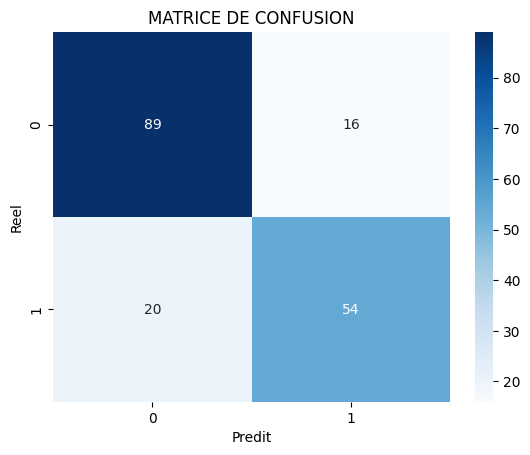

In [26]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

conf_matr = confusion_matrix(y_test, y_pred)
sns.heatmap(conf_matr, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predit')
plt.ylabel('Reel')
plt.title('MATRICE DE CONFUSION')
plt.show()


<span style="color:blue"><u>**3.4-Visualisation**<u></span>

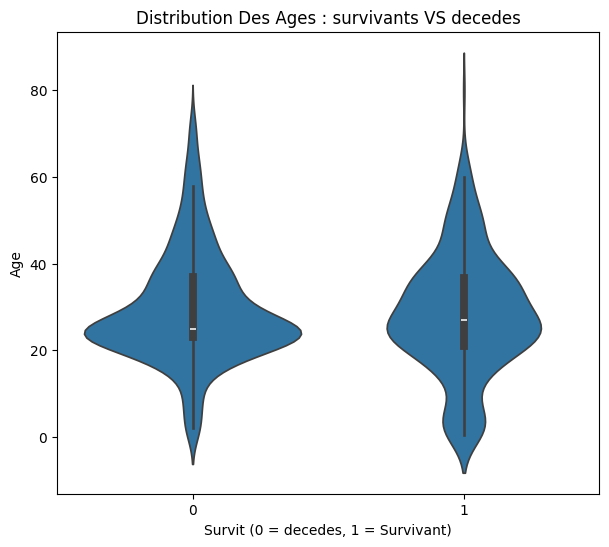

In [27]:
plt.figure(figsize=(7,6))
sns.violinplot(x='Survived', y='Age', data=df)
plt.title("Distribution Des Ages : survivants VS decedes")
plt.xlabel("Survit (0 = decedes, 1 = Survivant)")
plt.ylabel("Age")
plt.show()

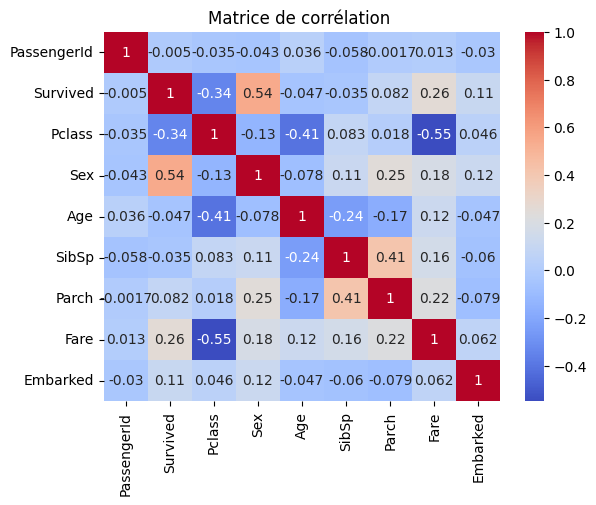

In [28]:
corr_matrix = df.corr(numeric_only=True)
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')
plt.title('Matrice de corrélation ')
plt.show()

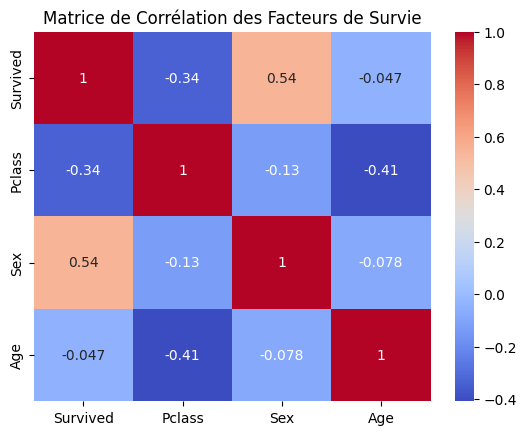

In [29]:
corr = df[["Survived", "Pclass", "Sex", "Age"]].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.title("Matrice de Corrélation des Facteurs de Survie")
plt.show()

<span style="color:blue"><u>**4-Conclusion**<u></span>

En conclusion, cette étude démontre que le naufrage du Titanic n'était pas un événement aléatoire, mais un phénomène régi par des dynamiques sociodémographiques, le sexe et la classe sociale étant les variables les plus déterminantes. Ainsi les résultats confirment l'hypothese de « les femmes et les enfants d'abord », avec des taux de survie atteignant 100 % pour les enfants des deux premières classes.
Le violin plot souligne également une protection accrue des plus jeunes passagers malgré une hécatombe chez les adultes.
Enfin, la robustesse du modèle prédictif est validée par la matrice de confusion, qui affiche une majorité de prédictions correctes (143/179), prouvant l'efficacité de l'algorithme pour identifier les profils des survivants.

 

<span style="color:blue"><u>**5-Bilan**<u></span>

Au cours de ce projet, j’ai réalisé une étude complète sur le dataset Titanic, en passant par plusieurs étapes, depuis l’acquisition et le nettoyage des données jusqu’à l’analyse exploratoire et la modélisation prédictive.

Dans un premier temps, j’ai procédé à l’identification et au traitement des valeurs manquantes, notamment dans les colonnes Age et Embarked. Les valeurs manquantes de la variable Age ont été remplacées par la médiane calculée selon la classe sociale (Pclass), afin de préserver la cohérence des profils des passagers. Les variables catégorielles Sex et Embarked ont ensuite été encodées en valeurs numériques, tandis que les colonnes inutiles ou trop incomplètes, comme Cabin, ont été supprimées. Un fichier cleaning_log.txt a également été généré afin de documenter les différentes modifications apportées au dataset.

Dans un deuxième temps, j’ai réalisé une analyse sociologique des facteurs susceptibles d’influencer la survie des passagers, en examinant notamment l’hypothèse « Les femmes et les enfants d’abord ». Les taux de survie ont été comparés selon le sexe, l’âge (enfants et adultes) et la classe sociale (Pclass). Les résultats ont mis en évidence des différences importantes entre ces catégories, montrant notamment un taux de survie plus élevé chez les femmes et les enfants, ainsi qu'une influence significative de la classe sociale. Un tableau récapitulatif a été généré et exporté afin de présenter clairement les taux de survie par catégorie.

La troisième étape a porté sur la visualisation des données et la modélisation prédictive. Un Violin Plot a été utilisé pour comparer la distribution des âges entre les survivants et les non-survivants, tandis qu'une Heatmap de corrélation a permis d'examiner les relations linéaires entre les variables numériques. J’ai ensuite développé un modèle de classification basé sur l’algorithme Random Forest, en utilisant la bibliothèque Scikit-learn. Les données ont été réparties en deux ensembles : 80 % pour l'entraînement (Train) et 20 % pour le test (Test). Une matrice de confusion a été générée afin d'évaluer les prédictions et d'identifier les erreurs de classification. Enfin, une fonction predire_survie(age, sexe, classe) a été développée pour estimer la probabilité de survie d'un passager à partir de ses caractéristiques.

La réalisation de ce projet m'a également permis de découvrir et de maîtriser de nouvelles fonctionnalités de Scikit-learn, notamment l'utilisation de Random Forest pour les problèmes de classification, ainsi que d'approfondir mes compétences en préparation des données, analyse statistique et interprétation des résultats.

En définitive, ce projet m'a permis de consolider mes compétences en Data Analysis, Data Visualization et Machine Learning, tout en développant une meilleure compréhension de l'exploitation des données pour identifier des tendances et construire des modèles prédictifs.